# Outputs for 6th Mag LGS

## Setup Materials

In [13]:
import matplotlib.pyplot as plt
import numpy as np
from paarti.utils import maos_utils
from paarti import psfs, psf_plots
from pathlib import Path

# psf_x = [0, 5, 10, 15, 20, 25, 30, 35]  # arcsec
# psf_y = [0, 0,  0,  0,  0,  0,  0,  0,  0,  0]  # arcsec
# psf_wvl = [432, 544, 652, 810, 877, 1020, 1248, 1673, 2200]

directory = '/Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TRICK_on_sky/outputs/A_table1_left_col_run3'
seed = 1

%matplotlib inline

# Strehl vs. Radius

In [14]:
if directory[-1] != '/':
    directory += '/'
mets = maos_utils.get_psf_metrics_over_field(directory, seed=seed)
x, y, w, strehl, fwhm_g, fwhm_e, r_ee50, r_ee80 = mets

Looking in /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TRICK_on_sky/outputs/A_table1_left_col_run3/ for simulation results...
xx =  8.6 yy =  0.0


In [15]:
# Expect [left, middle, right] H band strehls to be [34.7, 28.6, and 36.3] percent, respectively. Seeing [1.32%, 12.16%, and 18.73% respectively]
r = np.sqrt(x**2 + y**2)
print(r.shape)
print(r)
print(w)
print(strehl)
print("H band Strehl:", round(strehl[0][-2], 4))

(1, 5)
[[8.6 8.6 8.6 8.6 8.6]]
[[0.8  1.   1.25 1.65 2.12]]
[[0.08723283 0.1965907  0.34491485 0.53792022 0.68501349]]
H band Strehl: 0.5379


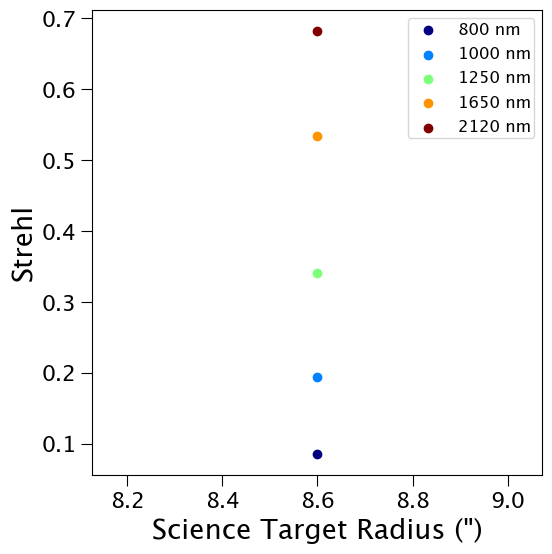

In [5]:
n_wvl = r.shape[1]
colors = plt.cm.jet(np.linspace(0,1,n_wvl))

plt.figure(1)

for ww in range(n_wvl):
    label = f'{w[0, ww]*1e3:3.0f} nm'
    plt.scatter(r[:, ww], strehl[:, ww], color=colors[ww], label=label)    

plt.xlabel('Science Target Radius (")')
plt.ylabel('Strehl')
# plt.axvline(10, linestyle='--', color='grey', label="KLGS constellation radius")
# plt.text(31, 0.2, 'LGS radius', color='grey')
# plt.title('2026mar04 set 21 image 2')
plt.legend(fontsize=12)
plt.show()

## Look at sim traces

In [6]:
# Import maos scripts to read .bin files
import sys
sys.path.append('/u/nstieg/code/latest_maos/maos/')
from scripts import readbin
from astropy import units as u

# Read in closed-loop tip-tilt errors from the .bin file
p = Path(directory)
res_bin_file = list(p.glob("*Res_*.bin"))[0]
res = readbin.readbin(str(res_bin_file))
tt_vars = res[2][:, 1] * u.m * u.m # This should be WFV in tip/tilt
tt_errors_nm = np.sqrt(tt_vars).to(u.nm)

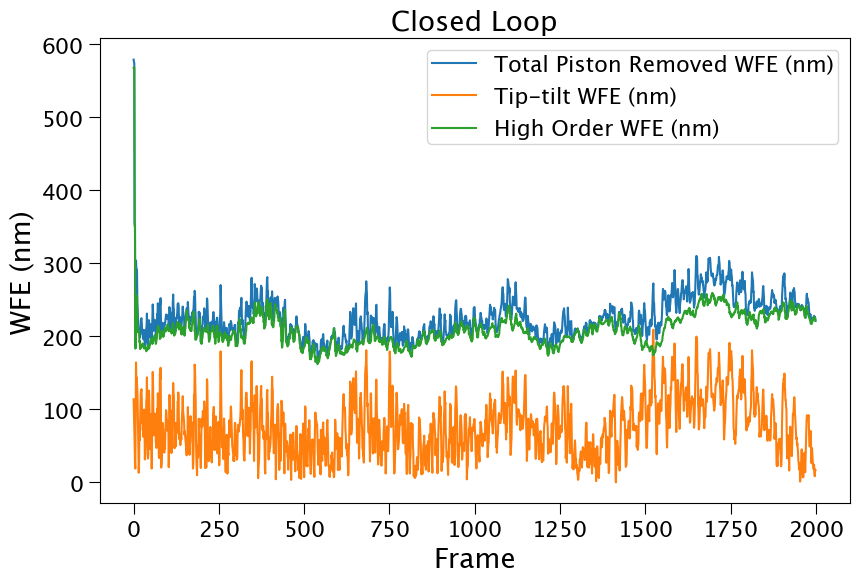

In [7]:
plt.figure(figsize=(10, 6))
plt.plot(np.sqrt(res[2][:, 0] * u.m * u.m).to(u.nm), label='Total Piston Removed WFE (nm)')
plt.plot(np.sqrt(res[2][:, 1] * u.m * u.m).to(u.nm), label='Tip-tilt WFE (nm)')
plt.plot(np.sqrt(res[2][:, 2] * u.m * u.m).to(u.nm), label='High Order WFE (nm)')
plt.title("Closed Loop")
plt.xlabel('Frame')
plt.ylabel('WFE (nm)')
plt.legend()
plt.show()

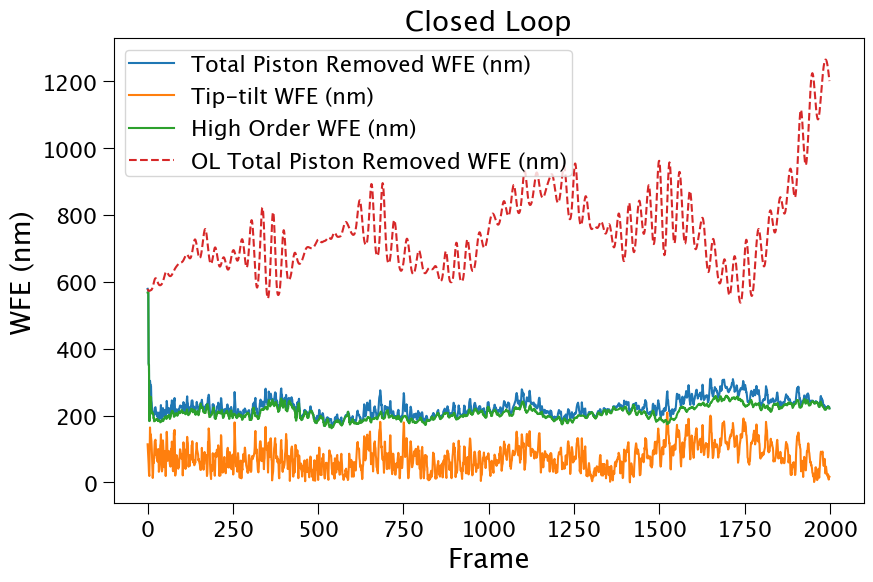

In [8]:
plt.figure(figsize=(10, 6))
plt.plot(np.sqrt(res[2][:, 0] * u.m * u.m).to(u.nm), label='Total Piston Removed WFE (nm)')
plt.plot(np.sqrt(res[2][:, 1] * u.m * u.m).to(u.nm), label='Tip-tilt WFE (nm)')
plt.plot(np.sqrt(res[2][:, 2] * u.m * u.m).to(u.nm), label='High Order WFE (nm)')
plt.plot(np.sqrt(res[0][:, 0] * u.m * u.m).to(u.nm), linestyle='--', label='OL Total Piston Removed WFE (nm)')
# plt.plot(np.sqrt(res[0][:, 1] * u.m * u.m).to(u.nm), linestyle='--', label='OL Tip-tilt WFE (nm)')
# plt.plot(np.sqrt(res[0][:, 2] * u.m * u.m).to(u.nm), linestyle='--', label='OL  High Order WFE (nm)')
plt.title("Closed Loop")
plt.xlabel('Frame')
plt.ylabel('WFE (nm)')
plt.legend()
plt.show()

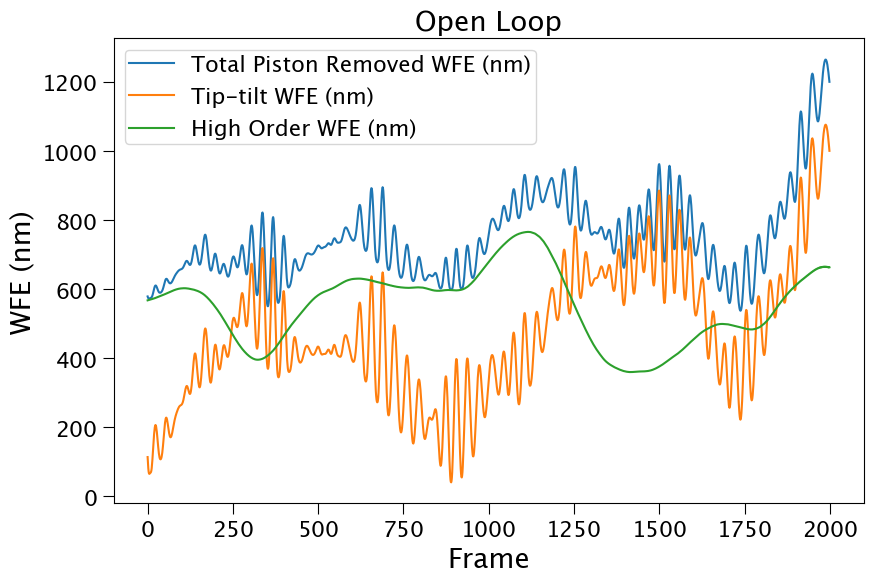

In [9]:
plt.figure(figsize=(10, 6))
plt.plot(np.sqrt(res[0][:, 0] * u.m * u.m).to(u.nm), label='Total Piston Removed WFE (nm)')
plt.plot(np.sqrt(res[0][:, 1] * u.m * u.m).to(u.nm), label='Tip-tilt WFE (nm)')
plt.plot(np.sqrt(res[0][:, 2] * u.m * u.m).to(u.nm), label='High Order WFE (nm)')
plt.title("Open Loop")
plt.xlabel('Frame')
plt.ylabel('WFE (nm)')
plt.legend()
plt.show()

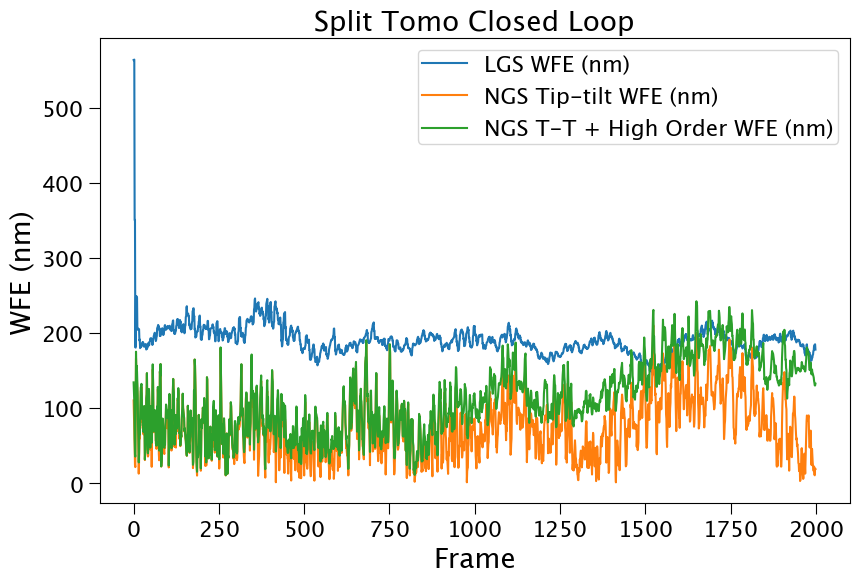

In [10]:
plt.figure(figsize=(10, 6))
plt.plot(np.sqrt(res[3][:, 0] * u.m * u.m).to(u.nm), label='LGS WFE (nm)')
plt.plot(np.sqrt(res[3][:, 1] * u.m * u.m).to(u.nm), label='NGS Tip-tilt WFE (nm)')
plt.plot(np.sqrt(res[3][:, 2] * u.m * u.m).to(u.nm), label='NGS T-T + High Order WFE (nm)')
plt.title("Split Tomo Closed Loop")
plt.xlabel('Frame')
plt.ylabel('WFE (nm)')
plt.legend()
plt.show()

## REduce Run 3

In [34]:
paper_H_band_strehls = [34.7, 28.6, 36.3] # percent
simulated_seeings = np.array([0.37, 0.21, 0.8]) * u.arcsec
simulated_r0s = np.array([0.27204656, 0.47932012, 0.12582153]) * u.m
paper_K_mags = [11.1, 11.5, 13.8]
evl_off_axis_distances = [8.6, 6.39, 0]


In [ ]:
# So we should have done 5 seeds for each of the 3 cols. Let's make an array to output hte H band strehls
num_cols = 3
num_seeds = 5
h_band_strehl_array = np.zeros((num_cols, num_seeds))

# Set params of the runs
run_num = 3
cols = ['left', 'middle', 'right']

# For each col and seed, read in the H band strehls and save to the array
for col_index in range(num_cols):
    for seed in range(1, num_seeds+1):
        print(f"Reading col {cols[col_index]}, seed {seed}...")
        dir = Path('/Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TRICK_on_sky/outputs/')
        output_directory = str(dir / f'A_table1_{cols[col_index]}_col_run{run_num}')
        if output_directory[-1] != '/':
            output_directory += '/'
        mets = maos_utils.get_psf_metrics_over_field(output_directory, seed=seed)
        x, y, w, strehl, fwhm_g, fwhm_e, r_ee50, r_ee80 = mets
        h_band_strehl_array[col_index, seed-1] = strehl[0][-2] * 100 # Convert to percent
        print("H band Strehl:", round(strehl[0][-2], 4))

Reading col left, seed 1...
Looking in /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TRICK_on_sky/outputs/A_table1_left_col_run3/ for simulation results...
xx =  8.6 yy =  0.0
H band Strehl: 0.5379
Reading col left, seed 2...
Looking in /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TRICK_on_sky/outputs/A_table1_left_col_run3/ for simulation results...
xx =  8.6 yy =  0.0
H band Strehl: 0.4731
Reading col left, seed 3...
Looking in /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TRICK_on_sky/outputs/A_table1_left_col_run3/ for simulation results...
xx =  8.6 yy =  0.0
H band Strehl: 0.553
Reading col left, seed 4...
Looking in /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TRICK_on_sky/outputs/A_table1_left_col_run3/ for simulation results...
xx =  8.6 yy =  0.0
H band Strehl: 0.5476
Reading col left, seed 5...
Looking in /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TRICK_on_sky/outputs/A_table1_left_col_run3/ for simulation results..

In [32]:
# Get the mean and std of the H band strehls for each seed
h_band_strehl_mean = np.mean(h_band_strehl_array, axis=1)
h_band_strehl_std = np.std(h_band_strehl_array, axis=1)
print(h_band_strehl_mean)
print(h_band_strehl_std)

[53.55381513 70.49057113 24.27424607]
[3.25019869 1.02611421 2.90621351]


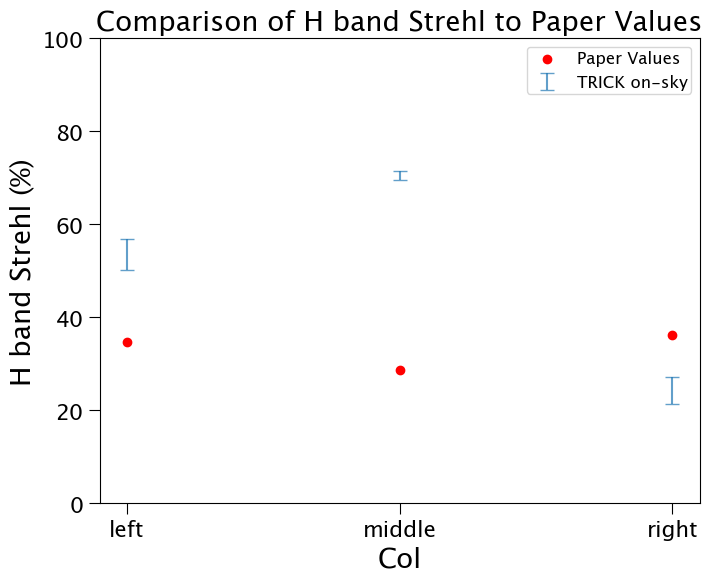

In [51]:
# Make a plot comparing the H band strehls for each col to the paper values
plt.figure(figsize=(8, 6))
col_indices = np.arange(num_cols)
plt.errorbar(col_indices, h_band_strehl_mean, yerr=h_band_strehl_std, capsize=5, alpha=0.7, label='TRICK on-sky', linestyle='')
plt.scatter(col_indices, paper_H_band_strehls, color='red', label='Paper Values', zorder=5)
plt.xticks(col_indices, cols)
plt.xlabel('Col')
plt.ylabel('H band Strehl (%)')
plt.title('Comparison of H band Strehl to Paper Values')
plt.legend(fontsize=12)
plt.ylim([0, 100])
plt.show()

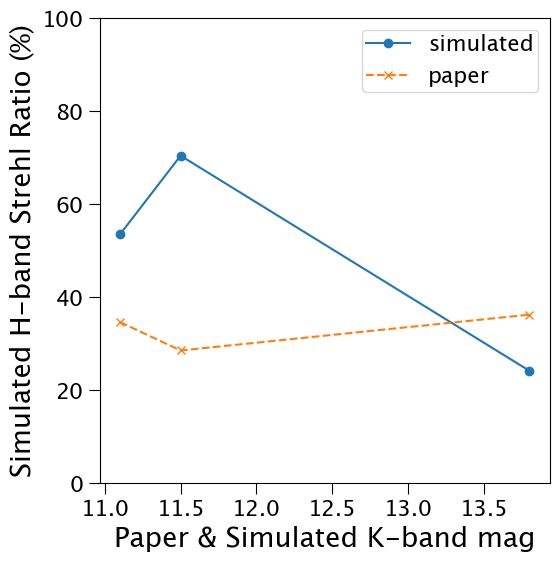

In [46]:
plt.plot(paper_K_mags, h_band_strehl_mean, marker='o', label="simulated")
plt.plot(paper_K_mags, paper_H_band_strehls, marker='x', label="paper", linestyle='--')
plt.xlabel("Paper & Simulated K-band mag")
plt.ylabel("Simulated H-band Strehl Ratio (%)")
# plt.title("H-band Strehl Ratio vs. Paper K-band Magnitude")
plt.legend()
plt.ylim([0, 100])

plt.show()

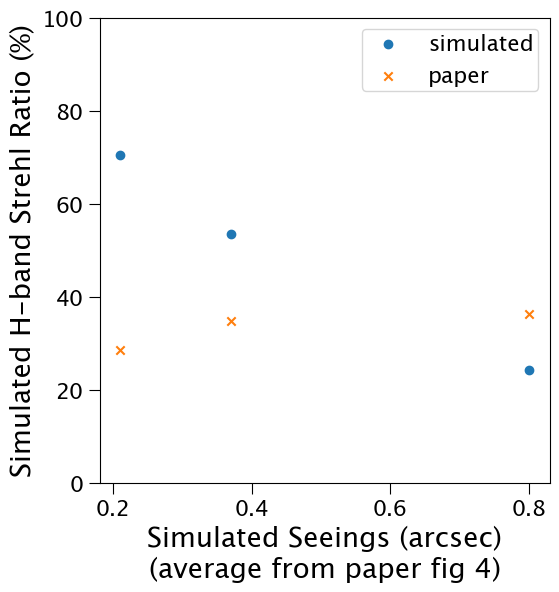

In [45]:
plt.scatter(simulated_seeings, h_band_strehl_mean, marker='o', label="simulated")
plt.scatter(simulated_seeings, paper_H_band_strehls, marker='x', label="paper")
plt.xlabel("Simulated Seeings (arcsec)\n(average from paper fig 4)")
plt.ylabel("Simulated H-band Strehl Ratio (%)")
# plt.title("H-band Strehl Ratio vs. Paper K-band Magnitude")
plt.ylim([0, 100])
plt.legend()
plt.show()

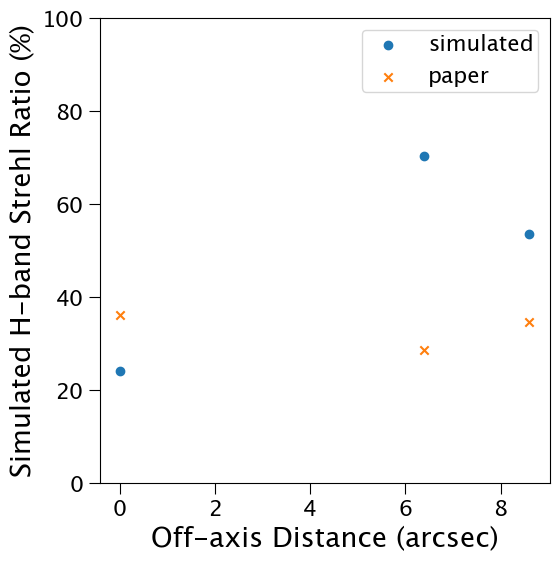

In [44]:
plt.scatter(evl_off_axis_distances, h_band_strehl_mean, marker='o', label="simulated")
plt.scatter(evl_off_axis_distances, paper_H_band_strehls, marker='x', label="paper")
plt.xlabel("Off-axis Distance (arcsec)")
plt.ylabel("Simulated H-band Strehl Ratio (%)")
# plt.title("H-band Strehl Ratio vs. Paper K-band Magnitude")
plt.ylim([0, 100])
plt.legend()
plt.show()

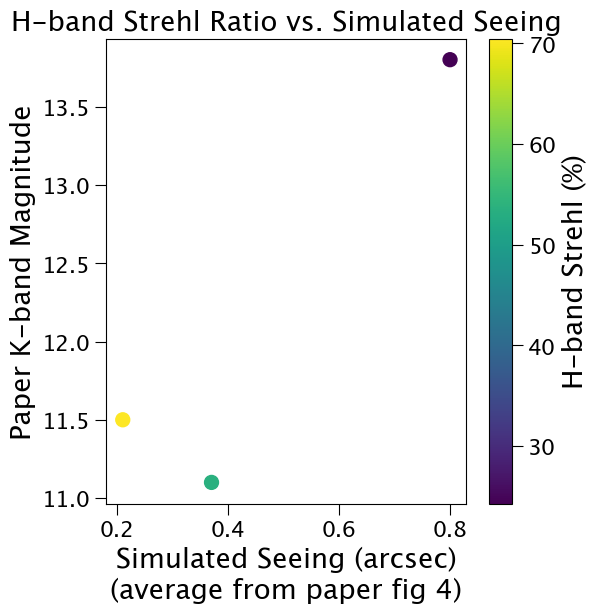

In [36]:
plt.scatter(simulated_seeings, paper_K_mags, c=h_band_strehl_mean, cmap='viridis', s=100)
plt.xlabel("Simulated Seeing (arcsec)\n(average from paper fig 4)")
plt.ylabel("Paper K-band Magnitude")
plt.title("H-band Strehl Ratio vs. Simulated Seeing")
plt.colorbar(label="H-band Strehl (%)")
plt.show()